# AIMHRA Backend Model Visualization

This notebook summarizes the main Django models in the backend and draws the relational structure between them.

Key domains represented in the backend:
- Authentication and roles
- Patient records and assignments
- Clinical assessments, predictions, and alerts
- Reports
- Chat conversations and RAG metadata
- Knowledge base documents and chunks
- ML model registry and audit logs


In [9]:
import os

os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
import django
django.setup()
print("Django initialized successfully.")


Django initialized successfully.


In [10]:
from django.apps import apps

models = apps.get_models()
for model in sorted(models, key=lambda m: (m._meta.app_label, m.__name__)):
    print(f"{model._meta.app_label}.{model.__name__}: {len(model._meta.fields)} fields")
print(f"\nTotal models: {len(models)}")


accounts.User: 14 fields
admin.LogEntry: 8 fields
assessments.Alert: 11 fields
assessments.Assessment: 16 fields
assessments.Prediction: 10 fields
audit.AuditLog: 8 fields
auth.Group: 2 fields
auth.Permission: 4 fields
chat.ChatMessage: 8 fields
chat.ChatSession: 6 fields
contenttypes.ContentType: 3 fields
kb.DocumentChunk: 8 fields
kb.KnowledgeDocument: 11 fields
mlcore.ModelVersion: 12 fields
patients.PatientAssignment: 5 fields
patients.PatientProfile: 24 fields
reports.Report: 6 fields
sessions.Session: 3 fields
token_blacklist.BlacklistedToken: 3 fields
token_blacklist.OutstandingToken: 6 fields

Total models: 20


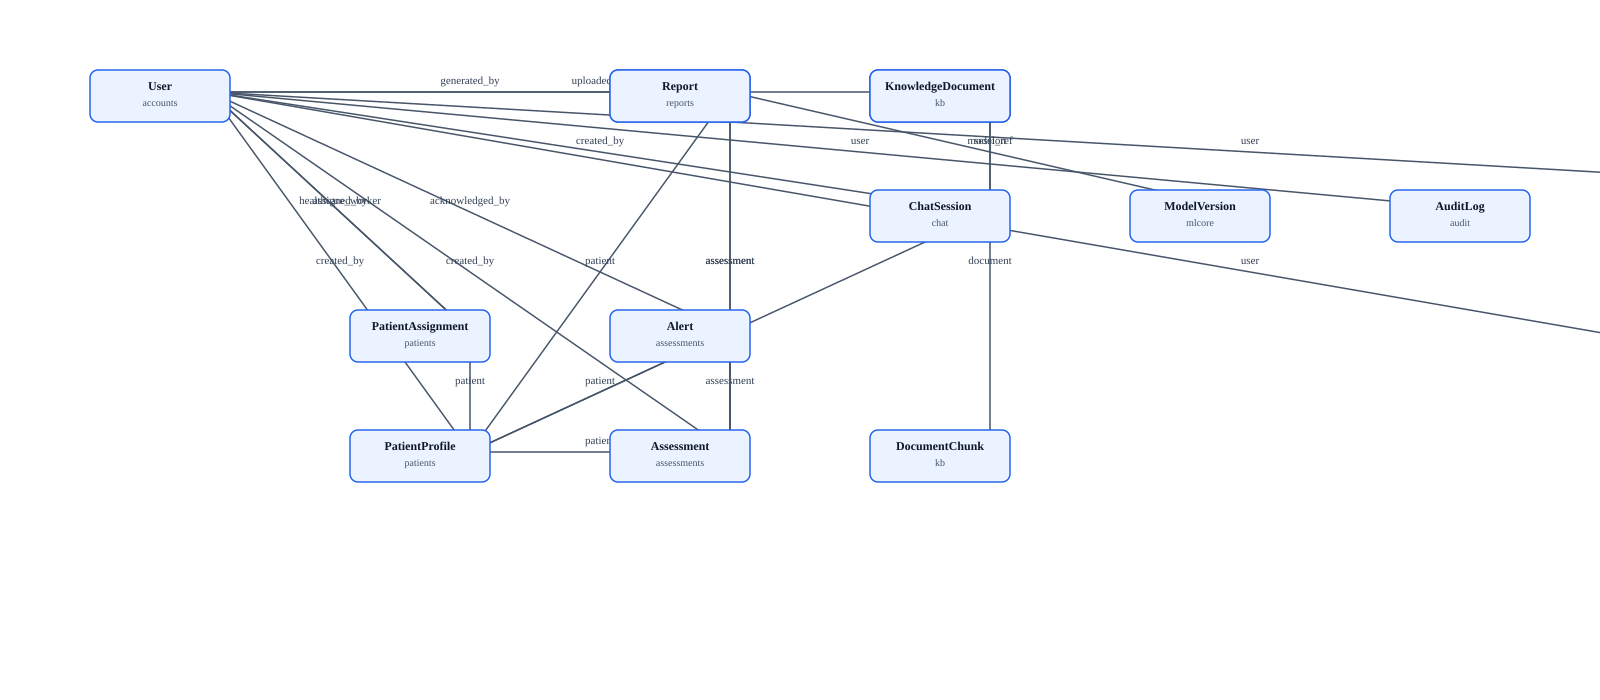

In [11]:
from django.db.models import ForeignKey, OneToOneField
from IPython.display import SVG, display
import html

all_models = sorted(apps.get_models(), key=lambda m: (m._meta.app_label, m.__name__))
app_columns = {
    "accounts": 0,
    "patients": 1,
    "assessments": 2,
    "reports": 2,
    "chat": 3,
    "kb": 3,
    "mlcore": 4,
    "audit": 5,
}
positions = {}
for i, model in enumerate(all_models):
    col = app_columns.get(model._meta.app_label, len(app_columns))
    row = i % 4
    positions[model.__name__] = (col * 260 + 90, row * 120 + 70)

edges = []
for model in all_models:
    for field in model._meta.get_fields():
        if field.is_relation and field.concrete and field.related_model is not None and field.model is not field.related_model:
            if isinstance(field, (ForeignKey, OneToOneField)):
                edges.append((model.__name__, field.related_model.__name__, field.name))

svg_parts = [
    '<svg xmlns="http://www.w3.org/2000/svg" width="1600" height="700" viewBox="0 0 1600 700">',
    '<defs><marker id="arrow" markerWidth="10" markerHeight="8" refX="8" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#475569"/></marker></defs>',
]
for src, dst, label in edges:
    x1, y1 = positions[src]
    x2, y2 = positions[dst]
    x1 += 120
    x2 += 120
    y1 += 22
    y2 += 22
    svg_parts.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#475569" stroke-width="1.5" marker-end="url(#arrow)" />')
    mid_x = (x1 + x2) / 2
    mid_y = (y1 + y2) / 2 - 8
    svg_parts.append(f'<text x="{mid_x}" y="{mid_y}" font-size="11" fill="#334155" text-anchor="middle">{html.escape(label)}</text>')

for model in all_models:
    x, y = positions[model.__name__]
    label = html.escape(model.__name__)
    app = html.escape(model._meta.app_label)
    svg_parts.append(f'<rect x="{x}" y="{y}" width="140" height="52" rx="8" fill="#EAF3FF" stroke="#2563EB" stroke-width="1.5" />')
    svg_parts.append(f'<text x="{x + 70}" y="{y + 20}" font-size="12" font-weight="bold" text-anchor="middle" fill="#0F172A">{label}</text>')
    svg_parts.append(f'<text x="{x + 70}" y="{y + 36}" font-size="10" text-anchor="middle" fill="#475569">{app}</text>')

svg_parts.append('</svg>')
display(SVG(data='\n'.join(svg_parts)))


In [12]:
from collections import defaultdict

model_map = defaultdict(list)
for model in sorted(apps.get_models(), key=lambda m: (m._meta.app_label, m.__name__)):
    model_map[model._meta.app_label].append(model.__name__)

for app_label in sorted(model_map):
    models_in_app = ', '.join(model_map[app_label])
    print(f"{app_label}: {models_in_app}")


accounts: User
admin: LogEntry
assessments: Alert, Assessment, Prediction
audit: AuditLog
auth: Group, Permission
chat: ChatMessage, ChatSession
contenttypes: ContentType
kb: DocumentChunk, KnowledgeDocument
mlcore: ModelVersion
patients: PatientAssignment, PatientProfile
reports: Report
sessions: Session
token_blacklist: BlacklistedToken, OutstandingToken


## Relationship summary

- `User` owns the authentication/role layer.
- `PatientProfile` stores patient demographics and is linked to the creator (`created_by`) and healthcare workers via `PatientAssignment`.
- `Assessment` belongs to a patient and stores clinical inputs plus the prediction result.
- `Prediction` is the ML output for exactly one assessment and references the versioned model.
- `Alert` is derived from an assessment and patient, and tracks triage status and rule metadata.
- `Report` stores generated PDF artifacts tied to a patient and assessment.
- `ChatSession` and `ChatMessage` form the chat history tied to a patient and user.
- `KnowledgeDocument` and `DocumentChunk` manage the KB source documents and embeddings.
- `ModelVersion` tracks model lineage, training config, metrics, and activation state.
- `AuditLog` records user and system actions across the application.


In [13]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

project_root = Path.cwd()
if not (project_root / "Mathernal_Risk.csv").exists():
    project_root = project_root.parent
backend_dir = project_root / "backend"
if str(backend_dir) not in sys.path:
    sys.path.insert(0, str(backend_dir))

from mlcore.constants import FEATURES, FEATURE_LABELS, RISK_LEVELS
from mlcore.dataset import clean_dataset, load_raw_dataset

data_path = project_root / "Mathernal_Risk.csv"
df_raw = load_raw_dataset(data_path)
df_clean, cleaning = clean_dataset(df_raw)
df_clean["risk_level"] = pd.Categorical(df_clean["risk_level"], categories=RISK_LEVELS, ordered=True)
df_raw["risk_level"] = pd.Categorical(df_raw["risk_level"], categories=RISK_LEVELS, ordered=True)
print(f"Rows before cleaning: {len(df_raw)}")
print(f"Rows after cleaning: {len(df_clean)}")
print("Cleaning stats:", cleaning)


Rows before cleaning: 6103
Rows after cleaning: 6057
Cleaning stats: {'rows_in': 6103, 'exact_duplicates_dropped': 1, 'implausible_rows_dropped_by_feature': {'age': 1, 'body_temperature': 43, 'diastolic_bp': 1}, 'implausible_rows_dropped_total': 45, 'rows_out': 6057, 'class_distribution_out': {'mid risk': 2043, 'high risk': 2016, 'low risk': 1998}}


In [20]:

counts_before = df_raw["risk_level"].value_counts().reindex(RISK_LEVELS, fill_value=0)
counts_after = df_clean["risk_level"].value_counts().reindex(RISK_LEVELS, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#4C78A8", "#F58518", "#E45756"]

sns.barplot(x=counts_after.index, y=counts_after.values, palette=colors, ax=axes[0])
axes[0].set_title("Class distribution after cleaning")
axes[0].set_xlabel("Risk level")
axes[0].set_ylabel("Count")
for patch, value in zip(axes[0].patches, counts_after.values):
    axes[0].annotate(f"{value}", (patch.get_x() + patch.get_width() / 2, value), ha="center", va="bottom")

axes[1].pie(counts_after.values, labels=counts_after.index, autopct="%1.1f%%", startangle=90, colors=colors, wedgeprops={"edgecolor": "white"})
axes[1].set_title("Risk level mix (%)")
plt.tight_layout()


C:\Users\Acer\AppData\Local\Temp\ipykernel_17444\2795099612.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts_after.index, y=counts_after.values, palette=colors, ax=axes[0])


In [15]:

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, feature in zip(axes.flat, FEATURES):
    sns.histplot(df_clean[feature], bins=30, kde=True, color="#4C78A8", ax=ax)
    ax.set_title(FEATURE_LABELS[feature])
    ax.set_xlabel("")
plt.tight_layout()


In [16]:

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, feature in zip(axes.flat, FEATURES):
    sns.boxplot(data=df_clean, x="risk_level", y=feature, order=RISK_LEVELS, palette=["#4C78A8", "#F58518", "#E45756"], ax=ax)
    ax.set_title(FEATURE_LABELS[feature])
    ax.set_xlabel("")
plt.tight_layout()


C:\Users\Acer\AppData\Local\Temp\ipykernel_17444\121147657.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="risk_level", y=feature, order=RISK_LEVELS, palette=["#4C78A8", "#F58518", "#E45756"], ax=ax)
C:\Users\Acer\AppData\Local\Temp\ipykernel_17444\121147657.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="risk_level", y=feature, order=RISK_LEVELS, palette=["#4C78A8", "#F58518", "#E45756"], ax=ax)
C:\Users\Acer\AppData\Local\Temp\ipykernel_17444\121147657.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.

In [17]:

correlation = df_clean[FEATURES].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, ax=ax)
ax.set_title("Feature correlation heatmap")
plt.tight_layout()


In [18]:

comparison_df = pd.DataFrame({
    "Before cleaning": counts_before,
    "After cleaning": counts_after,
})
comparison_df["Removed"] = comparison_df["Before cleaning"] - comparison_df["After cleaning"]
comparison_df


,Before cleaning,After cleaning,Removed
risk_level,,,
low risk,2001,1998,3
mid risk,2043,2043,0
high risk,2059,2016,43


In [19]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

X = df_clean[FEATURES].to_numpy()
y = df_clean["risk_level"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
models = {
    "DecisionTree": DecisionTreeClassifier(random_state=42, max_depth=6, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=2, class_weight="balanced_subsample", random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=400, learning_rate=0.08, max_depth=6, subsample=0.9, colsample_bytree=0.8, random_state=42, eval_metric="mlogloss"
    ),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")
    hr_recall = recall_score(y_test, pred, labels=["high risk"], average="macro", zero_division=0)
    rows.append({"model": name, "accuracy": acc, "macro_f1": f1, "high_risk_recall": hr_recall})
    print(f"{name}: accuracy={acc:.3f}, macro_f1={f1:.3f}, high_risk_recall={hr_recall:.3f}")

comparison = pd.DataFrame(rows).sort_values("accuracy", ascending=False)
comparison


DecisionTree: accuracy=0.904, macro_f1=0.903, high_risk_recall=0.777
RandomForest: accuracy=0.991, macro_f1=0.991, high_risk_recall=0.993


ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1 2], got ['high risk' 'low risk' 'mid risk']

In [ ]:

comparison_plot = comparison.set_index("model")[["accuracy", "high_risk_recall"]].copy()
fig, ax = plt.subplots(figsize=(10, 5))
comparison_plot.plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"])
ax.set_title("Model comparison on held-out test set")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(title="Metric")
plt.tight_layout()


In [ ]:

from sklearn.metrics import confusion_matrix
import shap

chosen_model_name = comparison.iloc[0]["model"]
chosen_model = models[chosen_model_name]
y_pred = chosen_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=RISK_LEVELS)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=RISK_LEVELS, yticklabels=RISK_LEVELS, ax=ax)
ax.set_title(f"Confusion matrix ? {chosen_model_name}")
ax.set_xlabel("Predicted risk level")
ax.set_ylabel("Actual risk level")
plt.tight_layout()

explainer = shap.TreeExplainer(chosen_model)
shap_values = explainer.shap_values(X_test)
if isinstance(shap_values, list):
    shap_values = np.asarray(shap_values)
if np.asarray(shap_values).ndim == 3:
    shap_values = np.asarray(shap_values)[RISK_LEVELS.index("high risk"), :, :]

fig, ax = plt.subplots(figsize=(10, 5))
shap.summary_plot(shap_values, X_test, feature_names=FEATURES, plot_type="bar", show=False)
plt.tight_layout()


In [ ]:

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(y_test, classes=RISK_LEVELS)
proba = chosen_model.predict_proba(X_test)

fig, ax = plt.subplots(figsize=(7, 6))
for i, label in enumerate(RISK_LEVELS):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
    ax.plot(fpr, tpr, label=f"{label} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title(f"ROC curve for {chosen_model_name}")
ax.legend(loc="lower right")
plt.tight_layout()
